# Lab 10: How to measure an agent's latency and cost

**CPU | API key: `OPENAI_API_KEY` | Follows: Day 2 D2-M05, steps 5.1 to 5.7 (slides 126–161)**

The copilot works. Nobody has timed it or priced it yet. In this lab you measure it the way you would before showing
it to a support team: how long a rep waits for the first words and for the whole reply, how much that varies from run
to run, where the seconds go, how many model calls each answer really makes, and what one resolved case costs.

## Goal

Measure an agent from your own runs: time to first token and total time over ten runs (p50 and p95), the share of
each turn spent in the model and in tools, a ledger of every model call with its tokens, and the cost of a resolved
case, with the prompt cache read correctly. The moments that teach it: a timer that waited for the first text stopped at 1.18 s on the tool's JSON, while the rep's first words came at 2.45 s in the next run; a download-link question was answered in about a second in 5 of 5 runs because the copilot skipped the handbook, and no reply gave the rule; the saved thread showed 4 of a conversation's 9 model calls and 40% of its cost; and a long prompt was read from the cache in 1 of 5 calls without a `prompt_cache_key` and 5 of 5 with one. All from `gpt-4o-mini`, 12 Oct 2026.

## What you will learn

- How to time a streamed reply with `stream_mode="messages"` and `version="v2"`: time to first token against total
  time, and why only the model's own text counts as the first words.
- How to report p50 and p95 over ten runs for a direct answer and a tool-using answer, and what ten runs cannot tell
  you.
- How to keep a ledger of every model call and tool call with a callback, and split a turn's seconds into model time
  and tool time.
- How to count the calls a middleware makes, which the saved thread does not show, and tag runs with the rep and the
  feature so a cost can be attributed.
- How to price a call, a conversation and a resolved case from `usage_metadata` and the prices in `models.env`,
  cached tokens included.
- How to tell when OpenAI's prompt cache was used, below and above 1,024 tokens, and how a `prompt_cache_key` changes
  it.

| Part | What you do | Calls to OpenAI |
|---|---|---|
| A | Time one streamed reply: first chunk, first text and total; fix a timer that counts the wrong text | about 25 |
| B | Run a direct and a tool-using question ten times each and report p50 and p95 | about 45 |
| C | Keep a ledger of every call and split each turn into model time and tool time | about 23 |
| D | Count the summariser's calls the thread does not show, and tag runs with rep and feature | about 12 |
| E | Price a call, a ten-turn thread and a resolved case | about 18 |
| F | Read the prompt cache below and above 1,024 tokens, with and without a cache key | 15 |
| G | Choose the first cost control to add, and try one | 6 |

About 145 calls to `CHAT_MODEL` and 145,000 input tokens in our run, about 3 US cents with `gpt-4o-mini`. Handbook searches add a few embedding calls of a few tokens each.

## The first two cells

Every lab in this repository opens with the same two cells: **setup** finds the repository folder (on Colab it clones
the repository and installs the packages first), and **config** reads the model names from `models.env` and finds your
OpenAI key. Lab 00 explains both.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


⚠️ On Colab, run the setup cell first in a fresh session. If another cell loaded the old `openai` package before the
install, the first model call fails with `ImportError: cannot import name ... from 'openai...'`; use **Runtime →
Restart session** and run from the top.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


Every part calls `CHAT_MODEL`. Part E also reads the prices next to it in `models.env`, so a different model only
needs that file changed. Every handbook search adds a small embedding call to `EMBED_MODEL`.

The picture shows one tool-using turn and the four numbers this lab measures. The model is called three times: twice
it asks for a tool, the third time it writes the reply. The **first chunk** arrives early but holds no words (it is the
start of a tool call); the **first text** the rep can read only comes once the last call starts writing; **total time**
ends with the last word. The seconds in between split into **model time** and **tool time**.

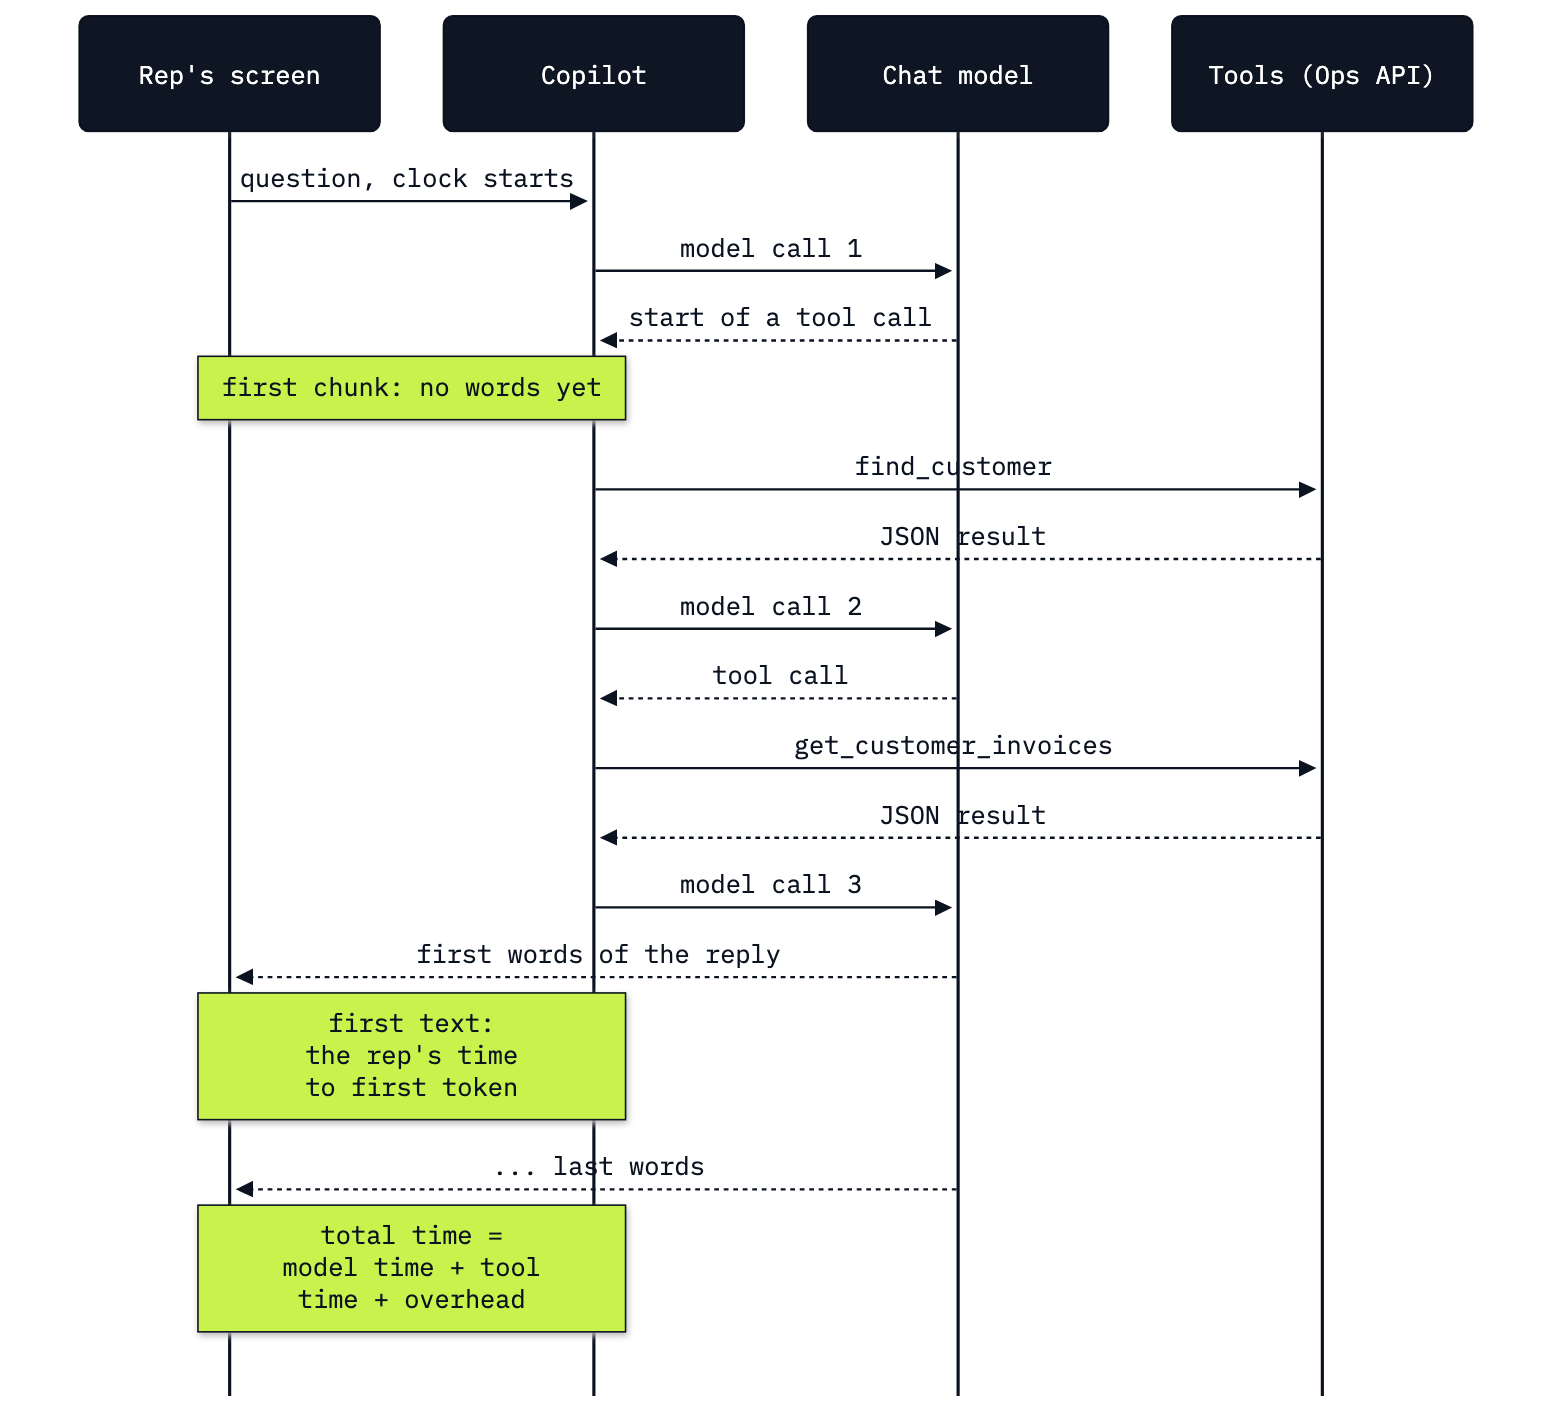

In [3]:
from IPython.display import Image
Image(filename=ROOT / "10_Latency_Streaming_And_Cost" / "resources" / "lab10_one_turn.png", width=640)

---

## Start the Ops API and build the copilot

The copilot reads the shop's data through the **Ops API** (Lab 00 Part D, Lab 07). Start it in this notebook; it runs
in a background thread until the last cell stops it.

In [4]:
from shared.ops_api import start_ops_api

server = start_ops_api()

Ops API started at http://127.0.0.1:8765


This is the copilot from Labs 07 and 08 with its four read tools, the Day 2 prompt and the rep's identity in the run's
context. Nothing here is new; this lab only measures it. The write tool joins in Part E, for the refund case.

In [5]:
from langchain.agents import create_agent
from shared.ops_tools import READ_TOOLS, RepContext, copilot_prompt
from shared.settings import chat_model

REP = RepContext("rep-42", "Jane Peacock")
copilot = create_agent(chat_model(settings), tools=READ_TOOLS, system_prompt=copilot_prompt(),
                       context_schema=RepContext)

DIRECT = "Make this sentence sound friendlier for a customer: 'Your refund is being processed.'"
TOOL_Q = "How many orders has Helena Holý placed, and what was her total spend?"
print([t.name for t in READ_TOOLS])

['search_policies', 'find_customer', 'get_customer_invoices', 'get_invoice']


Two questions, chosen so they behave differently. `DIRECT` needs no data: the copilot should answer in one model call.
`TOOL_Q` needs two lookups (find Helena, then list her invoices), so it should take three model calls and two tool
calls. Part C checks that this is what really happens.

---

## Part A: Time one streamed reply

A rep does not feel the total time first; they feel how long the screen stays empty. This part measures both, starting
with the plainest timer there is.

### Time a reply without streaming

`time.perf_counter()` reads a clock made for measuring short intervals. Read it before and after `invoke`, and the
difference is the seconds the rep would wait for the whole reply.

In [6]:
import time

t0 = time.perf_counter()
result = copilot.invoke({"messages": [("user", DIRECT)]}, context=REP)
seconds = time.perf_counter() - t0

print(result["messages"][-1].text)
print(f"{seconds:.2f} s")

You could say: "We're currently processing your refund, and we'll keep you updated!"
1.45 s


With `invoke` the screen shows nothing until the whole reply exists, so the first words and the last arrive at the
same moment. To show words as they are written, the copilot has to **stream**.

### Stream the same reply

`stream` runs the same agent but hands you pieces while it works. `stream_mode="messages"` asks for the model's
output token by token: each piece is a **chunk** of the message being written, with metadata saying which step of
the graph produced it. `version="v2"` is the current output format: every item is a dictionary with `type` (the
stream mode), `ns` (which graph it came from; empty for the top level) and `data`. For `"messages"`, `data` is the
pair `(chunk, metadata)`.

Print the first three items as they arrive, before timing anything.

In [7]:
parts = list(copilot.stream({"messages": [("user", DIRECT)]}, context=REP,
                            stream_mode="messages", version="v2"))
for part in parts[:3]:
    chunk, meta = part["data"]
    print(part["type"], part["ns"], "| node:", meta["langgraph_node"], "| text:", repr(chunk.text))
print(len(parts), "items in all")

messages () | node: model | text: ''
messages () | node: model | text: ''
messages () | node: model | text: 'You'
19 items in all


When we ran it (`gpt-4o-mini`, 12 Oct 2026), 19 items came back, all from the `model` node; the first two carried no text (the start of the message) and the third carried the first word, *You*. Each item carries a few characters of the reply in `chunk.text`, and `meta["langgraph_node"]` names
the step that produced it: `model` is the agent's model call.

**Time to first token (TTFT)** is the time from sending the request to the first piece of the reply arriving. For a
rep, the useful version is the first piece they can read, so this lab times three things: the **first chunk** of any
kind, the **first text** (the first chunk with words in it) and the **total**.

In [8]:
t0 = time.perf_counter()
first_chunk = first_text = None
for part in copilot.stream({"messages": [("user", DIRECT)]}, context=REP,
                           stream_mode="messages", version="v2"):
    chunk, meta = part["data"]
    now = time.perf_counter() - t0
    if first_chunk is None:
        first_chunk = now
    if chunk.text and first_text is None:
        first_text = now
total = time.perf_counter() - t0
print(f"first chunk {first_chunk:.2f} s | first text {first_text:.2f} s | total {total:.2f} s")

first chunk 0.54 s | first text 0.56 s | total 0.92 s


Ours: first chunk 0.54 s, first text 0.56 s, total 0.92 s. For a one-call answer the first words arrive after about 60% of the total time, and the rest of the reply streams in after them.

### Does streaming make the reply faster?

Predict before you run: if the same question is sent five times with `invoke` and five times with `stream`, which has
the shorter total? The cell alternates the two, so a slow minute on the network hits both.

In [9]:
from statistics import median

invoke_totals, stream_totals, stream_firsts = [], [], []
for _ in range(5):
    t0 = time.perf_counter()
    copilot.invoke({"messages": [("user", DIRECT)]}, context=REP)
    invoke_totals.append(time.perf_counter() - t0)

    t0, first = time.perf_counter(), None
    for part in copilot.stream({"messages": [("user", DIRECT)]}, context=REP,
                               stream_mode="messages", version="v2"):
        if part["data"][0].text and first is None:
            first = time.perf_counter() - t0
    stream_totals.append(time.perf_counter() - t0)
    stream_firsts.append(first)

print(f"invoke: median total {median(invoke_totals):.2f} s")
print(f"stream: median total {median(stream_totals):.2f} s, median first text {median(stream_firsts):.2f} s")

invoke: median total 0.90 s
stream: median total 0.95 s, median first text 0.66 s


When we ran it, the median total was 0.90 s with `invoke` and 0.95 s with `stream`, and the first text came at a median of 0.66 s. Streaming does not make the model faster. It changes when the rep starts reading, which is why
OpenAI's latency guide calls it the most effective way to make users wait less.

### Time a tool-using reply

Now `TOOL_Q`, with the same timer. Predict: the copilot must look Helena up and list her invoices before it can write
anything. When should the first text arrive?

In [10]:
t0 = time.perf_counter()
first_chunk = first_text = None
for part in copilot.stream({"messages": [("user", TOOL_Q)]}, context=REP,
                           stream_mode="messages", version="v2"):
    chunk, meta = part["data"]
    now = time.perf_counter() - t0
    if first_chunk is None:
        first_chunk = now
    if chunk.text and first_text is None:
        first_text, first_words, first_node = now, chunk.text, meta["langgraph_node"]
total = time.perf_counter() - t0
print(f"first chunk {first_chunk:.2f} s | first text {first_text:.2f} s | total {total:.2f} s")
print("the 'first text' came from node", repr(first_node), "and was:", first_words[:120])

first chunk 0.76 s | first text 1.18 s | total 5.06 s
the 'first text' came from node 'tools' and was: [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic", "support_rep": "Steve Johnson"}]


Ours: first chunk 0.76 s, *first text* 1.18 s, total 5.06 s, and that *first text* came from the `tools` node: Helena's customer record as JSON. The timer is wrong, and nothing failed. `stream_mode="messages"` streams the messages of **every**
step, and the `tools` step produces a tool message: the API's JSON answer. The rep never sees it as a reply, but
`chunk.text` is not empty, so the timer stopped there.

The fix is to count text only from the `model` step. The cell also records each tool call the model starts: a
chunk from the model can carry `tool_call_chunks`, and the first one for a call holds the tool's name.

In [11]:
t0 = time.perf_counter()
first_chunk = first_text = None
tools_called = []
for part in copilot.stream({"messages": [("user", TOOL_Q)]}, context=REP,
                           stream_mode="messages", version="v2"):
    chunk, meta = part["data"]
    now = time.perf_counter() - t0
    if first_chunk is None:
        first_chunk = now
    if meta["langgraph_node"] != "model":
        continue                                  # tool results are not words for the rep
    for call in chunk.tool_call_chunks:
        if call.get("name"):
            tools_called.append(call["name"])
    if chunk.text and first_text is None:
        first_text = now
total = time.perf_counter() - t0
print(f"first chunk {first_chunk:.2f} s | first text {first_text:.2f} s | total {total:.2f} s")
print("tools:", tools_called)

first chunk 0.60 s | first text 2.45 s | total 2.60 s
tools: ['find_customer', 'get_customer_invoices']


Ours: first chunk 0.60 s, first text 2.45 s, total 2.60 s, after `find_customer` and `get_customer_invoices`. The rep waited almost two and a half seconds for a word, not 1.18. The first chunk arrived quickly because it was the start of the first tool call, which a rep cannot
read. A tool-using turn spends most of its time before any text exists, so a page that streams only the reply still
looks frozen; Lab 13 streams the tool steps for that reason.

Every piece of the timer has now been run and checked, so it can become one function. `time_turn` runs one question
and returns the three times, the tools the model called and the reply. Parts B and C call it many times.

In [12]:
def time_turn(agent, question):
    # One streamed turn: first chunk, first model text, total seconds, tools called, reply.
    t0 = time.perf_counter()
    first_chunk = first_text = None
    tools_called, reply = [], ""
    for part in agent.stream({"messages": [("user", question)]}, context=REP,
                             stream_mode="messages", version="v2"):
        chunk, meta = part["data"]
        now = time.perf_counter() - t0
        if first_chunk is None:
            first_chunk = now
        if meta["langgraph_node"] != "model":
            continue
        for call in chunk.tool_call_chunks:
            if call.get("name"):
                tools_called.append(call["name"])
        if chunk.text:
            reply += chunk.text
            if first_text is None:
                first_text = now
    total = time.perf_counter() - t0
    return {"first_chunk": round(first_chunk, 3), "ttft": round(first_text or total, 3),
            "total": round(total, 3), "tools": tools_called, "reply": reply}

time_turn(copilot, TOOL_Q)

{'first_chunk': 0.546,
 'ttft': 2.362,
 'total': 2.679,
 'tools': ['find_customer', 'get_customer_invoices'],
 'reply': 'Helena Holý has placed 7 orders, with a total spend of $49.62.'}

### The newer streaming interface

The LangChain streaming page now recommends **event streaming** for new applications: `stream_events(...,
version="v3")` returns a run object whose `messages` yields one stream per model call, each with its own `text`, so
there is no node to filter. It exists in the pinned `langgraph` 1.2.12, which prints a warning that it is
experimental there (the cell prints the warning). This lab times with `stream(..., version="v2")`, the stable interface Lab 13's page also uses;
the cell shows the same turn through the new one so you can recognise it.

In [13]:
import warnings

t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    run = copilot.stream_events({"messages": [("user", TOOL_Q)]}, context=REP, version="v3")
    for number, message in enumerate(run.messages, start=1):
        first = None
        for delta in message.text:
            if first is None:
                first = time.perf_counter() - t0
        usage = message.output.usage_metadata
        shown = "no text" if first is None else f"first text {first:.2f} s"
        print(f"model call {number}: {shown}, {usage['input_tokens']} input tokens")
print(f"total {time.perf_counter() - t0:.2f} s")
print(*sorted({f"{w.category.__name__}: {w.message}" for w in caught}), sep="\n")

model call 1: no text, 764 input tokens


model call 2: no text, 824 input tokens


model call 3: first text 3.09 s, 1068 input tokens
total 3.44 s


Ours: three model calls, the first two with no text (they asked for tools), the third with its first text at 3.09 s; 764, 824 and 1,068 input tokens; then the warning that the v3 protocol is experimental. No node filter is needed, because each model call is its own stream.

### Checkpoint A

| Check | You should see |
|---|---|
| `DIRECT` streamed | first text a fraction of a second before the total (ours: first text 0.56 s, total 0.92 s) |
| `invoke` against `stream` | about the same median total (ours: 0.90 s and 0.95 s) |
| the first timer on `TOOL_Q` | a "first text" from the `tools` node: the API's JSON |
| the fixed timer | `find_customer` and `get_customer_invoices`, first text much later than the first chunk (ours: first chunk 0.60 s, first text 2.45 s) |

---

## Part B: Report p50 and p95 over ten runs

One run says little: the same request can take twice as long a minute later. This part runs each question ten times
and reports two numbers that describe the spread.

**p50**, the median, is the middle run: half the runs were faster. **p95** is the value 95% of runs stay under: it
describes the slow tail that one rep in twenty sees. A good median can hide a bad tail, so report both.

### Percentiles by hand

The **nearest-rank** method sorts the values and takes the one at position ⌈p/100 × n⌉. Try it on ten made-up times
before using it on real ones.

In [14]:
import math

def pct(values, p):
    # Nearest-rank percentile: sort, then take the value at position ceil(p/100 * n).
    ordered = sorted(values)
    return ordered[max(0, math.ceil(p / 100 * len(ordered)) - 1)]

times = [1.1, 0.9, 1.0, 4.2, 1.2, 0.8, 1.0, 1.3, 0.9, 1.1]
print("sorted:", sorted(times))
print("p50:", pct(times, 50), "| p95:", pct(times, 95))

sorted: [0.8, 0.9, 0.9, 1.0, 1.0, 1.1, 1.1, 1.2, 1.3, 4.2]
p50: 1.0 | p95: 4.2


With ten values, p50 is the 5th smallest and p95 is the 10th: **the slowest run**. One slow run (4.2 here) sets the
p95 on its own, and the next ten runs could give a very different one. Ten runs are enough to see the shape; they are
not enough to promise a target. That is why a p95 from a small sample should be measured again before anyone sets a
target from it.

### Ten runs of each question

Predict: which question has the higher p50 for first text, and which has the wider gap between p50 and p95?

In [15]:
runs = {"direct": [], "tool": []}
for number in range(1, 11):
    for name, question in (("direct", DIRECT), ("tool", TOOL_Q)):
        row = time_turn(copilot, question)
        runs[name].append(row)
    print(f"run {number:2}: direct ttft {runs['direct'][-1]['ttft']:.2f} total {runs['direct'][-1]['total']:.2f}"
          f" | tool ttft {runs['tool'][-1]['ttft']:.2f} total {runs['tool'][-1]['total']:.2f}"
          f" tools {len(runs['tool'][-1]['tools'])}")

run  1: direct ttft 0.66 total 0.94 | tool ttft 2.90 total 3.13 tools 2


run  2: direct ttft 0.70 total 0.95 | tool ttft 2.70 total 3.05 tools 2


run  3: direct ttft 0.69 total 0.92 | tool ttft 2.35 total 2.62 tools 2


run  4: direct ttft 0.57 total 0.83 | tool ttft 2.34 total 2.61 tools 2


run  5: direct ttft 0.67 total 1.05 | tool ttft 2.53 total 2.79 tools 2


run  6: direct ttft 0.61 total 0.90 | tool ttft 2.38 total 2.57 tools 2


run  7: direct ttft 0.52 total 0.79 | tool ttft 3.31 total 3.70 tools 2


run  8: direct ttft 0.59 total 0.80 | tool ttft 2.52 total 2.81 tools 2


run  9: direct ttft 0.56 total 0.83 | tool ttft 2.81 total 3.11 tools 2


run 10: direct ttft 0.52 total 0.82 | tool ttft 3.14 total 3.44 tools 2


The two questions alternate in each run, so a slow moment on the network falls on both. Now the summary: p50 and
p95 for first text and for total, per question.

In [16]:
print(f"{'question':9}{'TTFT p50':>10}{'TTFT p95':>10}{'total p50':>11}{'total p95':>11}{'tool calls':>12}")
for name, rows in runs.items():
    ttft = [r["ttft"] for r in rows]
    total = [r["total"] for r in rows]
    calls = sorted({len(r["tools"]) for r in rows})
    print(f"{name:9}{pct(ttft, 50):>10.2f}{pct(ttft, 95):>10.2f}{pct(total, 50):>11.2f}{pct(total, 95):>11.2f}"
          f"{str(calls):>12}")

question   TTFT p50  TTFT p95  total p50  total p95  tool calls
direct         0.59      0.70       0.83       1.05         [0]
tool           2.53      3.31       2.81       3.70         [2]


A chart shows what the two numbers summarise: every run as a dot, with the p50 and p95 lines for first text.

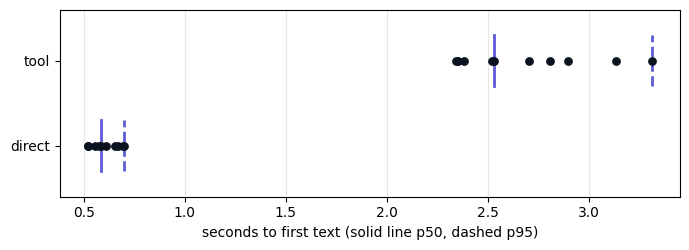

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 2.6))
for y, name in enumerate(("direct", "tool")):
    ttft = [r["ttft"] for r in runs[name]]
    ax.scatter(ttft, [y] * len(ttft), color="#0B1220", s=28, zorder=3)
    for p, style in ((50, "-"), (95, "--")):
        ax.plot([pct(ttft, p)] * 2, [y - 0.3, y + 0.3], style, color="#5B5BD6", lw=2)
ax.set_yticks([0, 1], ["direct", "tool"])
ax.set_xlabel("seconds to first text (solid line p50, dashed p95)")
ax.set_ylim(-0.6, 1.6)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

When we ran it (`gpt-4o-mini`, 12 Oct 2026), the direct question's first text came at p50 0.59 s and p95 0.70 s (run 2, the slowest), and the tool question's at p50 2.53 s and p95 3.31 s (run 7); it made 2 tool calls in all ten runs. Two lookups added about 1.9 seconds at the median, almost all of it the two extra model calls (Part C). Each p95 is one run: the next ten runs could put it elsewhere. Against the usual response-time limits (0.1 s feels instant, 1 s keeps the flow of thought, 10 s holds attention; Nielsen, 1993), the direct answer starts inside a second and the tool-using one does not, so a page should show the tool steps while the rep waits (Lab 13).

### Check what you timed

A fast answer is only good news if it is a right answer. This question asks for a reply about an expired download
link; the handbook's rule is that a link lasts 90 days and one new link lasts 7 days. Time it five times, and check in
code whether the reply contains the rule and whether the copilot searched the handbook.

In [18]:
import re

LINK_Q = "A customer's download link expired. Draft a short reply I can send."
for number in range(1, 6):
    row = time_turn(copilot, LINK_Q)
    has_rule = bool(re.search(r"\b(90|7|seven)[ -]days?\b", row["reply"]))
    print(f"run {number}: total {row['total']:.2f} s | tools {row['tools']} | names the rule: {has_rule}")
print("last reply:", row["reply"])

run 1: total 0.98 s | tools [] | names the rule: False


run 2: total 1.15 s | tools [] | names the rule: False


run 3: total 1.10 s | tools [] | names the rule: False


run 4: total 1.05 s | tools [] | names the rule: False


run 5: total 1.04 s | tools [] | names the rule: False
last reply: Sure! You can use this reply:

"I'm sorry to hear your download link expired. Please let me know the album you need, and I'll send you a new download link."


When we ran it, all five answered in about a second (0.98 to 1.15 s), none called a tool, and none named the 90 or 7 days; the last reply asked for the album and promised *a new download link*, without saying that it lasts 7 days. In a latency table these would look like the best runs. Latency and quality have to be read together: the cheapest way to make an agent faster is to let it
skip the work. Lab 11 turns checks like `has_rule` into an evaluation set.

### Checkpoint B

| Check | You should see |
|---|---|
| `pct` on the ten made-up times | p50 1.0, p95 4.2 (the slowest value) |
| the summary table | `direct` with 0 tool calls, `tool` with 2; the tool question's first text later than the direct one's (ours: direct 0.59 s, tool 2.53 s at p50) |
| the download-link question | fast, no tool call, and no 90 or 7 days in the reply in most runs (ours: 5 of 5 with no tool call, 0 of 5 naming the rule) |

---

## Part C: Keep a ledger of every call

Part B measured the turn from the outside. To make it faster or cheaper you need to see inside it: each model call and
each tool call, when it started, how long it took and how many tokens it used.

### Start from Lab 09's meter

Lab 09 counted calls with `Meter`, a **callback**: an object LangChain calls at events in a run. Its `on_llm_end` runs
after every chat model call and reads the call's `usage_metadata`. Here it is again, copied unchanged.

In [19]:
from langchain_core.callbacks import BaseCallbackHandler

class Meter(BaseCallbackHandler):
    # Counts every chat model call in a run, with its tokens, and the seconds since it was created.
    def __init__(self):
        self.calls, self.input_tokens, self.output_tokens = 0, 0, 0
        self.start = time.perf_counter()

    def on_llm_end(self, response, **kwargs):
        for generation in response.generations[0]:
            usage = generation.message.usage_metadata or {}
            self.calls += 1
            self.input_tokens += usage.get("input_tokens", 0)
            self.output_tokens += usage.get("output_tokens", 0)

    def read(self):
        return {"calls": self.calls, "input_tokens": self.input_tokens,
                "output_tokens": self.output_tokens, "seconds": round(time.perf_counter() - self.start, 1)}

meter = Meter()
copilot.invoke({"messages": [("user", TOOL_Q)]}, {"callbacks": [meter]}, context=REP)
meter.read()

{'calls': 3, 'input_tokens': 2656, 'output_tokens': 54, 'seconds': 2.8}

Ours: 3 calls, 2,656 input and 54 output tokens, 2.8 s. The totals are right, but they cannot say which call was slow, how much of the time the tools took,
or which call read from the prompt cache. For that you need one row per call.

### One row per call

`Ledger` keeps a row for every model call and every tool call. It notes the clock when a call starts
(`on_chat_model_start`, `on_tool_start`) and finishes the row when it ends (`on_llm_end`, `on_tool_end`); LangChain
gives every call a `run_id`, which pairs a start with its end. A model row also keeps the call's tokens, including
`cache_read`, the input tokens served from OpenAI's prompt cache (Part F), and its **source**: the graph step that
made it, or the `lc_source` a middleware puts in the call's metadata (Part D).

In [20]:
class Ledger(BaseCallbackHandler):
    # One row per model call and per tool call: when it started, how long it took, and a model call's tokens.
    def __init__(self):
        self.t0, self.open, self.rows = time.perf_counter(), {}, []

    def on_chat_model_start(self, serialized, messages, *, run_id, metadata=None, **kwargs):
        meta = metadata or {}
        self.open[run_id] = ("model", meta.get("lc_source") or meta.get("langgraph_node"), time.perf_counter())

    def on_tool_start(self, serialized, input_str, *, run_id, **kwargs):
        self.open[run_id] = ("tool", (serialized or {}).get("name"), time.perf_counter())

    def _close(self, run_id, **extra):
        kind, source, start = self.open.pop(run_id)
        self.rows.append({"kind": kind, "source": source, "start": round(start - self.t0, 3),
                          "seconds": round(time.perf_counter() - start, 3), **extra})

    def on_llm_end(self, response, *, run_id, **kwargs):
        usage = response.generations[0][0].message.usage_metadata or {}
        details = usage.get("input_token_details") or {}
        self._close(run_id, input=usage.get("input_tokens", 0), cached=details.get("cache_read", 0),
                    cache_write=details.get("cache_creation", 0), output=usage.get("output_tokens", 0))

    def on_tool_end(self, output, *, run_id, **kwargs):
        self._close(run_id)

    def model_rows(self):
        return [r for r in self.rows if r["kind"] == "model"]

    def tool_rows(self):
        return [r for r in self.rows if r["kind"] == "tool"]

Run `TOOL_Q` once with it and print the rows in the order they finished.

In [21]:
ledger = Ledger()
copilot.invoke({"messages": [("user", TOOL_Q)]}, {"callbacks": [ledger]}, context=REP)
for r in ledger.rows:
    tokens = f"in {r['input']:5} cached {r['cached']:5} out {r['output']:3}" if r["kind"] == "model" else ""
    print(f"{r['kind']:6}{r['source']:24}start {r['start']:6.2f} s  took {r['seconds']:5.2f} s  {tokens}")

model model                   start   0.00 s  took  0.84 s  in   764 cached     0 out  18
tool  find_customer           start   0.84 s  took  0.03 s  
model model                   start   0.87 s  took  0.81 s  in   824 cached     0 out  18
tool  get_customer_invoices   start   1.68 s  took  0.02 s  
model model                   start   1.70 s  took  0.87 s  in  1068 cached  1024 out  21


Ours: three model calls of 0.84, 0.81 and 0.87 s, and two tool calls of 0.03 and 0.02 s. Each model call is sent everything before it, so the input grows from 764 to 824 to 1,068 tokens. The third call read 1,024 of its tokens from the prompt cache: it passed 1,024 tokens and started like a recent request (Part F).

### Model time and tool time over five runs

Sum the model rows and the tool rows of each run, and compare their shares of the total.

In [22]:
shares = []
for number in range(1, 6):
    ledger = Ledger()
    t0 = time.perf_counter()
    copilot.invoke({"messages": [("user", TOOL_Q)]}, {"callbacks": [ledger]}, context=REP)
    total = time.perf_counter() - t0
    model_s = sum(r["seconds"] for r in ledger.model_rows())
    tool_s = sum(r["seconds"] for r in ledger.tool_rows())
    shares.append({"total": total, "model": model_s, "tool": tool_s})
    print(f"run {number}: total {total:.2f} s | model {model_s:.2f} s ({model_s / total:.0%})"
          f" | tools {tool_s:.3f} s ({tool_s / total:.1%}) | model calls {len(ledger.model_rows())}")
print(f"median: model {median(s['model'] for s in shares):.2f} s, tools {median(s['tool'] for s in shares):.3f} s")

run 1: total 2.84 s | model 2.78 s (98%) | tools 0.048 s (1.7%) | model calls 3


run 2: total 2.57 s | model 2.53 s (98%) | tools 0.035 s (1.4%) | model calls 3


run 3: total 2.58 s | model 2.51 s (97%) | tools 0.058 s (2.3%) | model calls 3


run 4: total 2.54 s | model 2.47 s (97%) | tools 0.057 s (2.2%) | model calls 3


run 5: total 3.66 s | model 3.60 s (98%) | tools 0.047 s (1.3%) | model calls 3
median: model 2.53 s, tools 0.048 s


When we ran it, model calls took 97 to 98% of every turn and the tools 1.3 to 2.3% (median 0.048 s). A faster Ops API would not help this copilot: to answer sooner it needs fewer model calls, shorter
inputs or shorter outputs.

A tool is not always cheap in time, though. `search_policies` embeds the question with `EMBED_MODEL` before it
searches the index, so it makes a network call of its own. Run a policy question once and read the tool row.

In [23]:
POLICY_Q = "A customer's download link expired. What does our policy say, and what should I reply?"
ledger = Ledger()
copilot.invoke({"messages": [("user", POLICY_Q)]}, {"callbacks": [ledger]}, context=REP)
for r in ledger.rows:
    print(f"{r['kind']:6}{r['source']:24}took {r['seconds']:5.2f} s")

model model                   took  1.08 s
tool  search_policies         took  0.71 s
model model                   took  1.22 s


Ours: `search_policies` took 0.71 s, more than twenty times the database tools (0.02 and 0.03 s) though less than either model call (1.08 and 1.22 s): the embedding request goes over the network to OpenAI. An embedding call does not pass through the chat model callbacks, so it shows up only inside the
tool's seconds; its cost is a few tokens of `EMBED_MODEL`, too small to matter here.

### Checkpoint C

| Check | You should see |
|---|---|
| `Meter` on `TOOL_Q` | 3 calls (ours: 3 calls, 2,656 input tokens) |
| the ledger | model, `find_customer`, model, `get_customer_invoices`, model; input tokens growing call by call |
| five runs | model time most of every turn, tools a few hundredths of a second (ours: model 97 to 98%, tools 0.035 to 0.058 s) |
| the policy question | `search_policies` slower than the database tools, because it calls the embedding model |

---

## Part D: Count the calls you do not see

A common shortcut is to price a conversation from the messages saved in its thread: every AI message carries its
`usage_metadata`. This part tests that shortcut on a copilot whose middleware makes model calls of its own.

### A copilot that summarises long threads

Lab 03 kept long threads short with `SummarizationMiddleware`: once the thread passes a token count, it asks a model
to summarise the older messages and keeps only the summary and the newest ones. The trigger here is low (1,500 tokens)
so it fires within five turns.

In [24]:
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver

summarising = create_agent(
    chat_model(settings), tools=READ_TOOLS, system_prompt=copilot_prompt(), context_schema=RepContext,
    middleware=[SummarizationMiddleware(model=chat_model(settings), trigger=("tokens", 1500), keep=("messages", 4))],
    checkpointer=InMemorySaver())

TURNS = ["I'm handling Helena Holý today. How many orders has she placed?",
         "What does our policy say about a disc that arrived cracked?",
         "She would like a replacement. Is that allowed?",
         "Draft a two-sentence reply I can send her.",
         "Before I close: how many orders did she place?"]

Run the five turns on one thread, with one ledger for the whole conversation.

In [25]:
thread = {"configurable": {"thread_id": "case-helena"}}
thread_ledger = Ledger()
for text in TURNS:
    result = summarising.invoke({"messages": [("user", text)]}, {**thread, "callbacks": [thread_ledger]}, context=REP)
    print(f"{text[:45]:47}→ {result['messages'][-1].text[:90]}")

I'm handling Helena Holý today. How many orde  → Helena Holý has placed 7 orders, totaling $49.62.


What does our policy say about a disc that ar  → If a disc arrives cracked, warped, or won't play, we replace it at no charge. The customer


She would like a replacement. Is that allowed  → Yes, a replacement is allowed since the disc arrived cracked [policy_damaged_media.md]. 




Draft a two-sentence reply I can send her.     → "I'm sorry to hear your disc arrived cracked. Please send me a photo of the damage, and I'


Before I close: how many orders did she place  → Helena Holý has placed 7 orders, totaling $49.62.


Now count the same conversation two ways: from the AI messages saved in the thread, and from the ledger. Predict
before you run: will they agree?

In [26]:
from collections import Counter

saved = [m for m in summarising.get_state(thread).values["messages"] if m.type == "ai" and m.usage_metadata]
print(f"saved thread: {len(saved)} model calls, {sum(m.usage_metadata['input_tokens'] for m in saved):6} input,"
      f" {sum(m.usage_metadata['output_tokens'] for m in saved):4} output tokens")

rows = thread_ledger.model_rows()
print(f"ledger:       {len(rows)} model calls, {sum(r['input'] for r in rows):6} input,"
      f" {sum(r['output'] for r in rows):4} output tokens")
print("ledger calls by source:", dict(Counter(r["source"] for r in rows)))

saved thread: 4 model calls,   5033 input,  164 output tokens
ledger:       9 model calls,  10029 input,  394 output tokens
ledger calls by source: {'model': 8, 'summarization': 1}


When we ran it (`gpt-4o-mini`, 12 Oct 2026), the saved thread held 4 AI messages with 5,033 input and 164 output tokens; the ledger counted 9 model calls with 10,029 input and 394 output tokens, one of them the summariser's. Priced from the thread, the conversation would look less than half as expensive as it was (Part E prices both).

Two things hide calls from the saved thread. The summariser's own call is never saved as an AI message: its result
becomes the summary. And the summary **replaces** the older messages, so the AI messages it summarised, with their
`usage_metadata`, are gone from the thread too. A bill built from the thread misses both; OpenAI charges for both. The
ledger sees every call because the callback fires on each one, the middleware's included (the summariser marks its
calls with `lc_source: "summarization"`).

### Tag runs with who and what

Counting is the first habit; the second is knowing **whose** spend it was. A run's config can carry `metadata` (keys
and values) and `tags` (labels). LangChain passes both to every call inside the run, so a callback or a tracer can add
up cost per rep, per feature or per thread. A small callback shows what each model call received.

In [27]:
class Received(BaseCallbackHandler):
    # What each chat model call received in its tags and metadata.
    def __init__(self):
        self.rows = []

    def on_chat_model_start(self, serialized, messages, *, tags=None, metadata=None, **kwargs):
        keep = {k: v for k, v in (metadata or {}).items() if k in ("rep_id", "feature", "thread_id")}
        self.rows.append({"tags": [t for t in tags or [] if not t.startswith("seq:")], **keep})

tagged = {"configurable": {"thread_id": "case-helena-tags"},
          "metadata": {"rep_id": REP.rep_id, "feature": "customer_lookup"}, "tags": ["copilot"]}
received = Received()
summarising.invoke({"messages": [("user", TOOL_Q)]}, {**tagged, "callbacks": [received]}, context=REP)
for row in received.rows:
    print(row)

{'tags': ['copilot'], 'rep_id': 'rep-42', 'feature': 'customer_lookup', 'thread_id': 'case-helena-tags'}
{'tags': ['copilot'], 'rep_id': 'rep-42', 'feature': 'customer_lookup', 'thread_id': 'case-helena-tags'}
{'tags': ['copilot'], 'rep_id': 'rep-42', 'feature': 'customer_lookup', 'thread_id': 'case-helena-tags'}


Ours: three model calls, each with the tag `copilot`, `rep_id` `rep-42`, `feature` `customer_lookup` and `thread_id` `case-helena-tags`. `thread_id` arrives without being listed in `metadata`: LangGraph adds it from `configurable`. In your
own app the rep's id comes from the sign-in, the same place `RepContext` gets it.

### Optional: send the run to LangSmith

A **trace** records one run as a tree of **spans** (one per model call and tool call) with inputs, outputs, timing and
tokens: the ledger above, kept for you, with a price table per model. LangSmith needs two environment variables,
`LANGSMITH_TRACING=true` and `LANGSMITH_API_KEY` (a secret: `.env` or Colab Secrets, never code). Its free plan keeps
5,000 traces a month for 14 days. If you have a key, set `RUN_LANGSMITH = True` and run the cell; the trace appears in
your LangSmith project with the tags and metadata above. Nothing later depends on it.

In [28]:
import os

RUN_LANGSMITH = False   # set to True if you have a LangSmith key

if RUN_LANGSMITH and load_key("LANGSMITH_API_KEY"):
    os.environ["LANGSMITH_TRACING"] = "true"
    summarising.invoke({"messages": [("user", TOOL_Q)]}, tagged, context=REP)
    os.environ["LANGSMITH_TRACING"] = "false"
    print("Sent one traced run; open your LangSmith project to read it.")
else:
    print("LangSmith skipped (RUN_LANGSMITH is False or no LANGSMITH_API_KEY found).")

LangSmith skipped (RUN_LANGSMITH is False or no LANGSMITH_API_KEY found).


In our run the switch was off: the lab was built without a LangSmith key, and nothing in it depends on the trace.

### Checkpoint D

| Check | You should see |
|---|---|
| the five turns | a reply to every turn; the last one still gives Helena's 7 orders |
| saved thread against ledger | fewer calls and tokens in the thread than in the ledger; at least one `summarization` call in the ledger (ours: 4 calls and 5,033 input tokens in the thread, 9 calls and 10,029 in the ledger, 1 `summarization` call) |
| tags and metadata | `copilot`, `rep-42`, `customer_lookup` and `case-helena-tags` on every model call |

---

## Part E: Price a call, a thread and a resolved case

Tokens become money through the model's price table. This part prices one call by hand, then a whole conversation,
then the unit a support manager cares about: one case, resolved.

### The prices

The prices live in `models.env` next to the model's name, in US dollars per million tokens, with the date they were
checked. Prices change: check them on OpenAI's pricing page in the week before you teach.

In [29]:
PRICE = {"input": float(settings["CHAT_PRICE_INPUT"]),
         "cached": float(settings["CHAT_PRICE_CACHED_INPUT"]),
         "cache_write": float(settings["CHAT_PRICE_CACHE_WRITE"]),
         "output": float(settings["CHAT_PRICE_OUTPUT"])}
print(settings["CHAT_MODEL"], PRICE)

gpt-4o-mini {'input': 0.15, 'cached': 0.075, 'cache_write': 0.15, 'output': 0.6}


Four kinds of token, four prices. **Input** is everything sent to the model. Part of it may be a **cache read**
(served from the prompt cache, cheaper) or a **cache write** (stored in the cache for later; at the input price on
`gpt-4o-mini`, at 1.25 times it on GPT-5.6 and later models). **Output** is what the model writes, and for a reasoning
model it includes the reasoning tokens you never see.

One trap: `input_tokens` already **includes** the cache reads and writes. Subtract them to get the fresh input, or the
cached tokens are paid twice. Price the last call of Part D's conversation by hand first.

In [30]:
row = thread_ledger.model_rows()[-1]
fresh = row["input"] - row["cached"] - row["cache_write"]
usd = (fresh * PRICE["input"] + row["cached"] * PRICE["cached"] + row["cache_write"] * PRICE["cache_write"]
       + row["output"] * PRICE["output"]) / 1_000_000
print(f"input {row['input']} = fresh {fresh} + cached {row['cached']} + written {row['cache_write']}; output {row['output']}")
print(f"cost ${usd:.6f}")

input 1111 = fresh 87 + cached 1024 + written 0; output 18
cost $0.000101


Ours: the last call of Part D sent 1,111 input tokens, 1,024 of them read from the cache, so only 87 were fresh; with 18 output tokens it cost $0.000101. The same arithmetic, as a function, for any ledger row:

In [31]:
def call_cost(row):
    # US dollars for one model call: fresh input, cache reads, cache writes and output, each at its price.
    fresh = row["input"] - row["cached"] - row["cache_write"]
    return (fresh * PRICE["input"] + row["cached"] * PRICE["cached"]
            + row["cache_write"] * PRICE["cache_write"] + row["output"] * PRICE["output"]) / 1_000_000

def priced(rows):
    return sum(call_cost(r) for r in rows)

print(f"last call ${call_cost(row):.6f} (same as by hand)")
print(f"Part D's conversation from the ledger: ${priced(thread_ledger.model_rows()):.6f}")
by_hand_from_thread = sum(call_cost({"input": m.usage_metadata["input_tokens"],
                                     "cached": m.usage_metadata["input_token_details"].get("cache_read", 0),
                                     "cache_write": m.usage_metadata["input_token_details"].get("cache_creation", 0),
                                     "output": m.usage_metadata["output_tokens"]}) for m in saved)
print(f"the same conversation from the saved thread: ${by_hand_from_thread:.6f}")

last call $0.000101 (same as by hand)
Part D's conversation from the ledger: $0.001482
the same conversation from the saved thread: $0.000594


Ours: $0.001482 from the ledger, $0.000594 from the saved thread: the thread showed 40% of what the five turns cost.

### Price a ten-turn thread

A practice ledger, made up to show growth, with no cache: every turn resends the whole thread, so input grows by 180
tokens a turn, and each reply is 60 tokens. Predict the total before you run the cell.

| Turn | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| Input | 600 | 780 | 960 | 1,140 | 1,320 | 1,500 | 1,680 | 1,860 | 2,040 | 2,220 |
| Output | 60 | 60 | 60 | 60 | 60 | 60 | 60 | 60 | 60 | 60 |

In [32]:
# ILLUSTRATIVE ledger: numbers chosen to show growth, no cache.
practice = [{"input": 600 + 180 * (turn - 1), "cached": 0, "cache_write": 0, "output": 60} for turn in range(1, 11)]
print("input tokens:", sum(r["input"] for r in practice), "| output tokens:", sum(r["output"] for r in practice))
print(f"all ten turns:       ${priced(practice):.6f}")
print(f"turn 10's call only: ${call_cost(practice[-1]):.6f}")

input tokens: 14100 | output tokens: 600
all ten turns:       $0.002475
turn 10's call only: $0.000369


Ours: 14,100 input and 600 output tokens, $0.002475 for the ten turns at `gpt-4o-mini`'s prices, against $0.000369 for turn 10's call alone, about a seventh. The most common pricing mistake is the second line: reading the last turn's input as the
conversation's input. Every turn resends the thread, so every turn is paid.

### Price a resolved case

A support manager does not buy model calls; they pay per case. Ticket 14 is the duplicate charge: the rep asks for
the rule, has the copilot check the two invoices and file the refund, approves it, and asks for a reply to paste. That
is three rep turns and one approval. The copilot now gets the write tool, with Lab 08's approval (approve, edit or
reject; never `respond`). This lab approves in code so it can price the case; Lab 08 shows the review screen a person
would read first.

In [33]:
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.types import Command
from shared.ops_tools import WRITE_TOOLS

CASE_TURNS = ["A customer says she was charged twice for the same album on the same day. What is our rule?",
              "Her invoices are 9001 and 9002. Check them and file the refund.",
              "Write the two-sentence reply I can paste to her."]

def case_agent():
    # The copilot with the write tool, Lab 08's approval and a checkpointer (a pause needs one).
    return create_agent(
        chat_model(settings), tools=READ_TOOLS + WRITE_TOOLS, system_prompt=copilot_prompt(),
        context_schema=RepContext, checkpointer=InMemorySaver(),
        middleware=[HumanInTheLoopMiddleware(interrupt_on={
            "file_refund_request": {"allowed_decisions": ["approve", "edit", "reject"]}})])

`resolve_case` sends the three turns to a fresh `case_agent()` on one thread and, whenever the run pauses at a refund,
approves every waiting request. `step` runs one turn or one resume with its own ledger and keeps a row for it.

In [34]:
def resolve_case(thread_id):
    # Ticket 14 end to end: three rep turns, approving any refund the copilot proposes. One row per step.
    agent, cfg, steps = case_agent(), {"configurable": {"thread_id": thread_id}}, []

    def step(label, payload):
        ledger = Ledger()
        out = agent.invoke(payload, {**cfg, "callbacks": [ledger]}, context=REP, version="v2")
        steps.append({"step": label, "rows": ledger.model_rows(),
                      "tools": [r["source"] for r in ledger.tool_rows()], "reply": out.value["messages"][-1].text})
        return out

    for text in CASE_TURNS:
        out = step(text, {"messages": [("user", text)]})
        while out.interrupts:
            waiting = out.interrupts[0].value["action_requests"]
            out = step("approve " + ", ".join(str(a["args"]) for a in waiting),
                       Command(resume={"decisions": [{"type": "approve"}] * len(waiting)}))
    return steps

Run the case three times, on three threads.

In [35]:
cases = [resolve_case(f"case-14-run-{run}") for run in (1, 2, 3)]

for s in cases[0]:
    rows = s["rows"]
    print(f"{s['step'][:44]:46}calls {len(rows)} | input {[r['input'] for r in rows]} | cached {[r['cached'] for r in rows]}"
          f" | ${priced(rows):.6f} | tools {s['tools']}")
print("reply:", cases[0][-1]["reply"])

A customer says she was charged twice for th  calls 2 | input [858, 1174] | cached [0, 0] | $0.000358 | tools ['search_policies']
Her invoices are 9001 and 9002. Check them a  calls 2 | input [1265, 1475] | cached [1152, 1152] | $0.000286 | tools ['get_invoice', 'get_invoice']
approve {'invoice_id': 9002, 'amount': 9.99,  calls 1 | input [1610] | cached [1408] | $0.000167 | tools ['file_refund_request']
Write the two-sentence reply I can paste to   calls 1 | input [1680] | cached [1536] | $0.000151 | tools []
reply: "I've filed a refund for the duplicate charge on your account. You'll receive a confirmation once it's approved."


When we ran it (`gpt-4o-mini`, 12 Oct 2026), run 1 took 6 model calls: two for the rule (with `search_policies`); two to read both invoices and propose the refund on 9002, where the run paused for approval; one after the approval, when the tool filed the request; and one for the reply. From the second turn on, most of each call's input was read from the cache (1,152 to 1,536 tokens): every call in one thread starts with the same system prompt, tools and earlier messages.

Now the three runs side by side: calls, tokens and cost per resolved case, and what the cache saved.

In [36]:
for run, steps in enumerate(cases, start=1):
    rows = [r for s in steps for r in s["rows"]]
    no_cache = priced([{**r, "cached": 0, "cache_write": 0} for r in rows])
    print(f"run {run}: {len(rows)} model calls | input {sum(r['input'] for r in rows):5} (cached {sum(r['cached'] for r in rows):5})"
          f" | output {sum(r['output'] for r in rows):3} | ${priced(rows):.6f} per case"
          f" (${no_cache:.6f} without the cache)")

run 1: 6 model calls | input  8062 (cached  5248) | output 242 | $0.000961 per case ($0.001355 without the cache)
run 2: 6 model calls | input  7917 (cached  4096) | output 253 | $0.001032 per case ($0.001339 without the cache)
run 3: 6 model calls | input  8019 (cached  5248) | output 243 | $0.000955 per case ($0.001349 without the cache)


Ours: 6 model calls in every run. Runs 1 and 3 read 5,248 cached tokens and cost $0.000961 and $0.000955 per case; run 2 read 4,096 (one call missed the cache) and cost $0.001032. Without the cache the same tokens would have cost $0.001339 to $0.001355, so the cache saved 23 to 29%. The number to watch is the call count, which sets everything else; the cache moves the price by a few percent from run to run.

Each approval runs `file_refund_request`, and the tool's key includes the thread, so three runs on three threads file
three requests for the same charge in the Ops API (Lab 08's lesson).

### From a case to a month

Multiply only after measuring. A scenario, not Chinook's data (Chinook has three support reps): a support centre of
1,000 reps, each resolving 40 cases a day like this one, for 22 working days.

In [37]:
# SCENARIO: the volume is made up; the cost per case is the median of the three runs above.
per_case = median(priced([r for s in steps for r in s["rows"]]) for steps in cases)
cases_per_month = 1_000 * 40 * 22
print(f"{cases_per_month:,} cases × ${per_case:.6f} = ${cases_per_month * per_case:,.2f} a month")

880,000 cases × $0.000961 = $845.59 a month


Ours: 880,000 cases at $0.000961 is $845.59 a month for the chat model alone; embeddings and any judge come on top. Reported per case, the number can be compared with what a case costs a person, and it moves when the
copilot changes: a prompt that adds one tool call to every case adds a model call's worth to every line of this sum.

### Checkpoint E

| Check | You should see |
|---|---|
| the last call priced by hand and by `call_cost` | the same number |
| the conversation priced from the thread and from the ledger | the thread's price lower (ours: $0.000594 against $0.001482) |
| the ten-turn ledger | 14,100 input and 600 output tokens; at `gpt-4o-mini`'s prices $0.002475, against $0.000369 for turn 10 alone |
| ticket 14 | about 6 model calls per case, cache reads from the second turn on, about a tenth of a cent per case (ours: 6 calls, $0.000955 to $0.001032) |

---

## Part F: Read the prompt cache

Part E's case read cached tokens, and Part B's single questions read none. This part finds out when OpenAI's prompt
cache is used, and what you can do about it.

**Prompt caching** is OpenAI's: when a request starts with the same tokens as a recent one (the same system prompt,
the same tools, the same earlier messages), the provider can reuse its work on that **prefix** and bill those tokens
at the cached-input price: half price on `gpt-4o-mini`, a tenth on GPT-5.6 and later. Nothing needs switching on.
Three conditions from OpenAI's guide matter here: the prefix must be identical; it must be at least 1,024 tokens long;
and the request must reach a machine that holds the cached prefix. On models before GPT-5.6, a stable
**`prompt_cache_key`** helps route related requests to the same machine. The cached count comes back in
`usage_metadata["input_token_details"]["cache_read"]`, rounded down to a multiple of 128.

### A short prefix and a long one

The short system prompt is the copilot's own. The long one adds the start of the support handbook, which takes it
past 1,024 tokens. The question stays the same.

In [38]:
from shared.copilot import HANDBOOK

SHORT_PROMPT = copilot_prompt()
LONG_PROMPT = copilot_prompt() + "\n\n# Handbook\n" + HANDBOOK.read_text()[:6000]
CACHE_Q = "In one sentence: how long does a download link last?"

def cache_test(system_prompt, cache_key=None, n=5):
    # Send the same request n times; return (input tokens, cached tokens) per call.
    kwargs = {"model_kwargs": {"prompt_cache_key": cache_key}} if cache_key else {}
    model = chat_model(settings, **kwargs)
    out = []
    for _ in range(n):
        usage = model.invoke([("system", system_prompt), ("user", CACHE_Q)]).usage_metadata
        out.append((usage["input_tokens"], usage["input_token_details"].get("cache_read", 0)))
    return out

`cache_test` sends one request `n` times in a row. With `cache_key`, the model client adds `prompt_cache_key` to every
request (`model_kwargs` passes extra fields to the API). Predict, for each of the three settings below: how many of
the five calls read from the cache?

In [39]:
import uuid

key = "lab10-" + uuid.uuid4().hex[:8]          # a new key each run, so nothing is cached from an earlier run
results = {"short prompt, no key": cache_test(SHORT_PROMPT),
           "long prompt, no key": cache_test(LONG_PROMPT),
           "long prompt, with a key": cache_test(LONG_PROMPT, cache_key=key)}
for name, calls in results.items():
    hits = sum(1 for _, cached in calls if cached)
    print(f"{name:25}input {calls[0][0]:5} | cached per call {[c for _, c in calls]} | {hits} of {len(calls)} read the cache")

short prompt, no key     input   576 | cached per call [0, 0, 0, 0, 0] | 0 of 5 read the cache
long prompt, no key      input  1868 | cached per call [0, 0, 0, 1664, 0] | 1 of 5 read the cache
long prompt, with a key  input  1868 | cached per call [1664, 1664, 1664, 1664, 1664] | 5 of 5 read the cache


When we ran it (`gpt-4o-mini`, 12 Oct 2026), the short prompt (576 input tokens) was never cached. The long prompt (1,868 tokens) read the cache in 1 of 5 calls without a key (the fourth), and in 5 of 5 with one, the first included, because the calls without a key had just stored the same prefix; each hit was 1,664 tokens (13 × 128). Four earlier runs the same day gave the same picture: without a key 0 of 19 calls cached, with one 15 of 19, every miss a first call. Inside one thread (Parts C, D and E) the cache was read without a key, probably because those calls followed each other within seconds and shared a growing prefix.

What one cache read saves on the long prompt, at the prices in `models.env`:

In [40]:
long_calls = results["long prompt, with a key"]
cached = max(c for _, c in long_calls)
miss = call_cost({"input": long_calls[0][0], "cached": 0, "cache_write": 0, "output": 30})
hit = call_cost({"input": long_calls[0][0], "cached": cached, "cache_write": 0, "output": 30})
print(f"miss ${miss:.6f} | hit ${hit:.6f} | saved {1 - hit / miss:.0%} per call (30 output tokens assumed)")

miss $0.000298 | hit $0.000173 | saved 42% per call (30 output tokens assumed)


Ours: $0.000298 for a miss and $0.000173 for a hit, 42% less per call. On `gpt-4o-mini` cached input is half price and the cache write costs nothing extra, so a hit can only save; on GPT-5.6 and later the first call pays 1.25 times for the write, and the saving needs reuse.

What this means for the copilot: keep the stable text first (system prompt, then tools, then the thread) so turns
share the longest possible prefix; never put a date or a request id at the top of the prompt; and on `gpt-4o-mini`
send a stable `prompt_cache_key` (one per prompt version, for example) when many short conversations share a long
prompt. Report what the run shows: caching is a likely discount, not a promise (Lab 06 saw it miss in most calls).

### Checkpoint F

| Check | You should see |
|---|---|
| short prompt | under 1,024 input tokens and no cache reads |
| long prompt, no key | over 1,024 input tokens; cache reads rare or absent (ours: 1 of 5) |
| long prompt, with a key | most calls cached, in multiples of 128; the first may miss (ours: 5 of 5, 1,664 tokens each) |

---

## Part G: Choose the first cost control to add

Measure first, then control, then optimise. This part puts the measurements in one place and tries the control they
point to.

In [41]:
direct_ttft = [r["ttft"] for r in runs["direct"]]
tool_ttft = [r["ttft"] for r in runs["tool"]]
case_costs = [priced([r for s in steps for r in s["rows"]]) for steps in cases]
print(f"first text, direct: p50 {pct(direct_ttft, 50):.2f} s, p95 {pct(direct_ttft, 95):.2f} s")
print(f"first text, tool:   p50 {pct(tool_ttft, 50):.2f} s, p95 {pct(tool_ttft, 95):.2f} s")
print(f"tool time share:    {median(s['tool'] / s['total'] for s in shares):.1%} of a tool-using turn (median)")
print(f"hidden calls:       {len(thread_ledger.model_rows()) - len(saved)} of {len(thread_ledger.model_rows())} calls not in the saved thread")
print(f"cost per case:      ${min(case_costs):.6f} to ${max(case_costs):.6f}")

first text, direct: p50 0.59 s, p95 0.70 s
first text, tool:   p50 2.53 s, p95 3.31 s
tool time share:    1.7% of a tool-using turn (median)
hidden calls:       5 of 9 calls not in the saved thread
cost per case:      $0.000955 to $0.001032


Six controls, and the lever each one pulls:

| Control | Pulls | Measured here |
|---|---|---|
| a call limit per run or per thread | number of calls | each tool call is one more model call (Part C) |
| a token budget per thread | tokens per case | the thread grows every turn (Parts D and E) |
| a project spend limit at OpenAI | the monthly total | the month is a multiplication (Part E) |
| model routing | price per token | one model here |
| stable prompt first, a cache key | cache reads | half price on cached input (Part F) |
| shorter replies | output tokens | output costs 4 times input on `gpt-4o-mini` |

Our choice for this copilot, from these numbers: a **call limit** first. Tools take about 2% of a turn and a case costs about a tenth of a cent, so faster tools or a cheaper model would change little; what can multiply the bill is a run that keeps calling the model, as Lab 09's policy handler did (up to 35 calls for one request), and every extra call also adds seconds the rep waits. A stable cache key comes second (cheap, a likely discount), shorter replies third. A token budget per thread (Challenge 1) refines the limit once you know your case sizes.

`ModelCallLimitMiddleware` is LangChain's built-in call limit. `thread_limit` counts the agent's model calls across
every turn of a thread; `exit_behavior="end"` stops the run instead of raising an error. Give Part D's five turns a
limit of 6 calls and read what the rep sees.

In [42]:
from langchain.agents.middleware import ModelCallLimitMiddleware

limited = create_agent(
    chat_model(settings), tools=READ_TOOLS, system_prompt=copilot_prompt(), context_schema=RepContext,
    middleware=[ModelCallLimitMiddleware(thread_limit=6, exit_behavior="end")], checkpointer=InMemorySaver())

limit_thread = {"configurable": {"thread_id": "case-helena-limited"}}
for text in TURNS:
    ledger = Ledger()
    result = limited.invoke({"messages": [("user", text)]}, {**limit_thread, "callbacks": [ledger]}, context=REP)
    print(f"{text[:45]:47}calls {len(ledger.model_rows())} → {result['messages'][-1].text[:80]}")

I'm handling Helena Holý today. How many orde  calls 3 → Helena Holý has placed a total of 7 orders. 

If you need any details about her 


What does our policy say about a disc that ar  calls 2 → If a CD or vinyl arrives cracked, warped, or will not play, we replace it at no 


She would like a replacement. Is that allowed  calls 1 → Yes, a replacement is allowed for a cracked disc, as it will be replaced at no c
Draft a two-sentence reply I can send her.     calls 0 → Model call limits exceeded: thread limit (6/6)
Before I close: how many orders did she place  calls 0 → Model call limits exceeded: thread limit (6/6)


When we ran it, turns 1 to 3 used 3, 2 and 1 calls (6 in all); turns 4 and 5 made no model call and returned *Model call limits exceeded: thread limit (6/6)*. The limit works, but the rep reads the middleware's own message, which says nothing about what to do
next. In a real copilot the limit is the trigger and the reply is yours: hand the case to a person with a sentence the
rep can act on. Challenge 1 writes that version as a token budget.

### Checkpoint G

| Check | You should see |
|---|---|
| the summary | the numbers from Parts B to E in one place |
| the call limit | the first turns answered, then *Model call limits exceeded: thread limit (6/6)* with no model call (ours: 3, 2 and 1 calls, then the message twice) |

In [43]:
server.should_exit = True

## What you can do now

- Time a streamed reply with `stream(..., stream_mode="messages", version="v2")`, count only the `model` step's text
  as the first words, and recognise `stream_events(version="v3")`.
- Report p50 and p95 over ten runs with the nearest-rank method, know that p95 of ten runs is the slowest run, and
  check the answers you timed.
- Keep a ledger of every model call and tool call with a callback, and say how much of a turn was the model and how
  much the tools.
- Count the calls a middleware makes, which the saved thread does not show, and tag runs with rep, feature and thread.
- Price a call, a conversation and a resolved case from `usage_metadata` and `models.env`, without paying cached
  tokens twice or pricing only the last turn.
- Read `cache_read`, explain why a prompt under 1,024 tokens is never cached, and use a stable `prompt_cache_key` on
  `gpt-4o-mini`.

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| Time to first text is close to the first chunk on a tool-using question | the timer counted a tool message: `stream_mode="messages"` streams the `tools` step too | count text only where `meta["langgraph_node"] == "model"` |
| `TypeError: cannot unpack non-iterable` or `KeyError: 'data'` in a stream loop | `version="v2"` items are dictionaries; without it, items are `(chunk, metadata)` tuples | use `part["data"]` with `version="v2"`, or unpack the tuple without it |
| `LangChainBetaWarning: The v3 streaming protocol on Pregel is experimental.` | `stream_events(version="v3")` in langgraph 1.2.12 | a warning, not an error; the lab times with `version="v2"` |
| `cache_read` is always 0 | the prefix is under 1,024 tokens, it changed between calls, or the requests reached different machines | put stable text first; on `gpt-4o-mini` send a stable `prompt_cache_key` |
| `KeyError: 'CHAT_PRICE_CACHE_WRITE'` | an older `models.env` | pull the repository again, or add the line from the current `models.env` |
| The saved thread gives fewer calls than your bill | middleware calls (the summariser) and summarised messages are not in the thread | count with a callback, or a tracer |
| `Model call limits exceeded: thread limit (6/6)` on every later turn | `thread_limit` counts the whole thread | start a new thread, or raise the limit |
| `The Ops API did not answer`, or `httpx.ConnectError` | the API is not running (a restarted kernel) | run the cell with `start_ops_api()` again |
| Your seconds differ a lot from ours | network, region and load | compare shapes and gaps (direct against tool, p50 against p95), not the seconds |

## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor; the results marked "ours" are
from its run (`gpt-4o-mini`, 12 Oct 2026).

1. **A token budget per thread, with a handover.** Write a `@before_model` middleware (Lab 03) that adds up
   `input_tokens` from the AI messages in the thread and, above a budget you choose, ends the run with your own message
   to the rep: the case goes to a person, and why. Return `{"messages": [AIMessage(...)], "jump_to": "end"}` and
   declare `@before_model(can_jump_to=["end"])`. Run Part D's five turns with a budget of 6,000 tokens. Expected: the
   handover at turn 4, with your message instead of a model call. Then add `SummarizationMiddleware` from Part D
   and say why the budget now hands over later than the ledger says it should. (ours: alone, the budget handed over before turn 4's first call, at 6,627 input tokens; with the summariser it never fired, while the ledger counted 10,379 input tokens over the five turns: the summary removed the AI messages the budget was adding up.)
2. **Stream progress, not only the reply.** Use `stream_mode=["messages", "updates"]` with `version="v2"` and print a
   line when the `model` step's update asks for a tool (`chunk["type"] == "updates"`). Time the first progress line and
   the first text for `TOOL_Q` over five runs. Expected: the first progress line within about a second, the first text
   seconds later. (ours: first progress line at a median of 0.98 s, first text at 2.39 s, over five runs.)
3. **How steady is p95?** Run `DIRECT` thirty times. Compute p95 over all thirty and over each block of ten. Expected:
   the three ten-run p95s differ from each other more than the p50s do, and the thirty-run p95 is the 29th value, not
   the slowest. (ours: ten-run p95s of 0.86, 0.93 and 0.75 s against p50s of 0.60, 0.62 and 0.58 s; over all thirty, p95 0.86 s, the 29th value, and the slowest 0.93 s.)

## Resources

- [LangChain: streaming](https://docs.langchain.com/oss/python/langchain/streaming): stream modes, `version="v2"`, streaming tool calls and progress
- [LangChain: event streaming](https://docs.langchain.com/oss/python/langchain/event-streaming): `stream_events(version="v3")` and its projections
- [LangChain: messages](https://docs.langchain.com/oss/python/langchain/messages): `usage_metadata` and message chunks
- [LangChain: built-in middleware](https://docs.langchain.com/oss/python/langchain/middleware/built-in): `SummarizationMiddleware`, `ModelCallLimitMiddleware`, `ToolCallLimitMiddleware`
- [OpenAI: latency optimization](https://developers.openai.com/api/docs/guides/latency-optimization): seven principles, streaming among them
- [OpenAI: prompt caching](https://developers.openai.com/api/docs/guides/prompt-caching): the 1,024-token minimum, `cached_tokens`, `prompt_cache_key`, differences by model
- [OpenAI: pricing](https://developers.openai.com/api/docs/pricing): the current price per model; check it before you teach
- [LangSmith: observability](https://docs.langchain.com/oss/python/langchain/observability): tracing an agent with two environment variables
- [OWASP LLM10:2025 Unbounded Consumption](https://genai.owasp.org/llmrisk/llm102025-unbounded-consumption/): why an uncapped loop is a cost risk and a security risk

Next: [Lab 11, how to evaluate an agent's replies](../11_Evaluation_Set/README.md). Back to [the lab list](../README.md).